In [21]:
import pandas as pd
import numpy as np
from google.colab import drive
from copy import deepcopy

In [2]:
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [13]:
df = pd.read_csv('/content/gdrive/MyDrive/DASS_project/data/youbike1.0_10min.csv')
df

,Unnamed: 0,total_num,current_num,empty,valid,time,dayofweek
0,0,30,6.0,22.0,1,2018-01-01 23:40:00,0
1,1,30,6.0,22.0,1,2018-01-01 23:40:00,0
2,2,30,6.0,22.0,1,2018-01-01 23:40:00,0
3,3,30,6.0,22.0,1,2018-01-01 23:40:00,0
4,4,30,6.0,22.0,1,2018-01-01 23:40:00,0
...,...,...,...,...,...,...,...
23755,23755,30,17.0,12.0,1,2018-06-14 23:10:00,3
23756,23756,30,17.0,12.0,1,2018-06-14 23:30:00,3
23757,23757,30,17.0,12.0,1,2018-06-14 23:30:00,3
23758,23758,30,13.0,16.0,1,2018-06-14 23:40:00,3


In [14]:
df['valid'].value_counts()

1    23730
0       30
Name: valid, dtype: int64

In [15]:
df['dayofweek'] = df['dayofweek'].apply(lambda x: x+1)

In [6]:
df

,Unnamed: 0,total_num,current_num,empty,valid,time,dayofweek
0,0,30,6.0,22.0,1,2018-01-01 23:40:00,1
1,1,30,6.0,22.0,1,2018-01-01 23:40:00,1
2,2,30,6.0,22.0,1,2018-01-01 23:40:00,1
3,3,30,6.0,22.0,1,2018-01-01 23:40:00,1
4,4,30,6.0,22.0,1,2018-01-01 23:40:00,1
...,...,...,...,...,...,...,...
23755,23755,30,17.0,12.0,1,2018-06-14 23:10:00,4
23756,23756,30,17.0,12.0,1,2018-06-14 23:30:00,4
23757,23757,30,17.0,12.0,1,2018-06-14 23:30:00,4
23758,23758,30,13.0,16.0,1,2018-06-14 23:40:00,4


In [16]:
df = df.drop('Unnamed: 0', axis = 1)
df

,total_num,current_num,empty,valid,time,dayofweek
0,30,6.0,22.0,1,2018-01-01 23:40:00,1
1,30,6.0,22.0,1,2018-01-01 23:40:00,1
2,30,6.0,22.0,1,2018-01-01 23:40:00,1
3,30,6.0,22.0,1,2018-01-01 23:40:00,1
4,30,6.0,22.0,1,2018-01-01 23:40:00,1
...,...,...,...,...,...,...
23755,30,17.0,12.0,1,2018-06-14 23:10:00,4
23756,30,17.0,12.0,1,2018-06-14 23:30:00,4
23757,30,17.0,12.0,1,2018-06-14 23:30:00,4
23758,30,13.0,16.0,1,2018-06-14 23:40:00,4


In [17]:
# create week day 
def weekday(x):
  if x <= 5:
    return 1
  else:
    return 0

df['isWeekday'] = np.zeros(df.shape[0])
df['isWeekday'] = df['isWeekday'].apply(weekday)
df['isWeekday']

0        1
1        1
2        1
3        1
4        1
        ..
23755    1
23756    1
23757    1
23758    1
23759    1
Name: isWeekday, Length: 23760, dtype: int64

In [18]:
# create weekend 
def weekend(x):
  if x <= 5:
    return 0
  else:
    return 1

df['isWeekend'] = np.zeros(df.shape[0])
df['isWeekend'] = df['isWeekend'].apply(weekend)
df['isWeekend']

0        0
1        0
2        0
3        0
4        0
        ..
23755    0
23756    0
23757    0
23758    0
23759    0
Name: isWeekend, Length: 23760, dtype: int64

In [20]:
# day of weeek onehot
df = df.join(pd.get_dummies(df['dayofweek'], prefix = 'dayofweek'))
df.columns


Index([  'total_num', 'current_num',       'empty',       'valid',
              'time',   'dayofweek',   'isWeekday',   'isWeekend',
                   1,             2,             3,             4,
                   5,             6,             7],
      dtype='object')

In [ ]:
# 10 min before class


In [25]:
# cols = ['current_num', 'valid', 'dayofweek', 'isWeekday', 'isWeekend', '1', '2', '3', '4', '5', '6', '7']
df2 = df.copy(deep = True)
df2 = df2.set_index('time')
df2

,total_num,current_num,empty,valid,dayofweek,isWeekday,isWeekend,1,2,3,4,5,6,7
time,,,,,,,,,,,,,,
2018-01-01 23:40:00,30,6.0,22.0,1,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,30,6.0,22.0,1,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,30,6.0,22.0,1,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,30,6.0,22.0,1,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,30,6.0,22.0,1,1,1,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-06-14 23:10:00,30,17.0,12.0,1,4,1,0,0,0,0,1,0,0,0
2018-06-14 23:30:00,30,17.0,12.0,1,4,1,0,0,0,0,1,0,0,0
2018-06-14 23:30:00,30,17.0,12.0,1,4,1,0,0,0,0,1,0,0,0


In [28]:
df2 = df2.drop(['total_num', 'empty', 'dayofweek'], axis = 1)
df2

,current_num,valid,isWeekday,isWeekend,1,2,3,4,5,6,7
time,,,,,,,,,,,
2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0
2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
2018-06-14 23:10:00,17.0,1,1,0,0,0,0,1,0,0,0
2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,0,0
2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,0,0


In [30]:
df2.reset_index(inplace = True)

In [31]:
df2

,time,current_num,valid,isWeekday,isWeekend,1,2,3,4,5,6,7,morning
0,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0,0.0
1,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0,0.0
2,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0,0.0
3,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0,0.0
4,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
23755,2018-06-14 23:10:00,17.0,1,1,0,0,0,0,1,0,0,0,0.0
23756,2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,0,0,0.0
23757,2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,0,0,0.0
23758,2018-06-14 23:40:00,13.0,1,1,0,0,0,0,1,0,0,0,0.0


In [33]:
df2['time'] = pd.to_datetime(df2['time'])

In [36]:
# create morning...
def morning(x):
  if x.hour <= 12 and x.hour >= 6:
    return 1
  else:
    return 0
def midnight(x):
  if x.hour <= 6 and x.hour >= 0:
    return 1
  else:
    return 0
def afternoon(x):
  if x.hour <= 18 and x.hour >= 12:
    return 1
  else:
    return 0
def night(x):
  if x.hour <= 24 and x.hour >= 18:
    return 1
  else:
    return 0

df2['morning'] = np.zeros(df2.shape[0])
df2['morning'] = df2['time'].apply(morning)
df2['morning']
# df2['midnight']
df2['midnight'] = np.zeros(df2.shape[0])
df2['midnight'] = df2['time'].apply(midnight)

df2['afternoon'] = np.zeros(df2.shape[0])
df2['afternoon'] = df2['time'].apply(afternoon)

df2['night'] = np.zeros(df2.shape[0])
df2['night'] = df2['time'].apply(night)

In [48]:
df2['time2'] = np.zeros(df2.shape[0])
df2['time2'] = df2['time'].apply(lambda x : x.strftime( '%X' ) )

In [49]:
df2['time2']

0        23:40:00
1        23:40:00
2        23:40:00
3        23:40:00
4        23:40:00
           ...   
23755    23:10:00
23756    23:30:00
23757    23:30:00
23758    23:40:00
23759    23:50:00
Name: time2, Length: 23760, dtype: object

In [51]:
# time dummies
df2 = df2.join(pd.get_dummies(df2['time2'], prefix = 'time'))
df2.columns

Index([         'time',   'current_num',         'valid',     'isWeekday',
           'isWeekend',               1,               2,               3,
                     4,               5,
       ...
       'time_22:20:00', 'time_22:30:00', 'time_22:40:00', 'time_22:50:00',
       'time_23:00:00', 'time_23:10:00', 'time_23:20:00', 'time_23:30:00',
       'time_23:40:00', 'time_23:50:00'],
      dtype='object', length=161)

In [52]:
df2

,time,current_num,valid,isWeekday,isWeekend,1,2,3,4,5,...,time_22:20:00,time_22:30:00,time_22:40:00,time_22:50:00,time_23:00:00,time_23:10:00,time_23:20:00,time_23:30:00,time_23:40:00,time_23:50:00
0,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23755,2018-06-14 23:10:00,17.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
23756,2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
23757,2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
23758,2018-06-14 23:40:00,13.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0


In [53]:
df2.to_csv('/content/gdrive/MyDrive/DASS_project/data/youbike1.0_0102ver2.csv')

In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [40]:
def Xysplit(df):
  X, y = df.drop(['current_num'], axis=1, inplace=False), df['current_num']
  return X, y
def split(X, y):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42)
  return X_train, X_test, y_train, y_test

# def normalize(X_train, X_test):
#   cols = ['測站氣壓(hPa)', '海平面氣壓(hPa)', '氣溫(℃)',
#        '相對溼度(%)', '風速(m/s)', '最大陣風(m/s)', '降水量(mm)', '降水時數(h)',
#        '全天空日射量(MJ/㎡)',  '紫外線指數']
#   scaler = StandardScaler()
#   scaler.fit(X_train[cols])
#   X_train[cols] = scaler.transform(X_train[cols])
#   X_test[cols] = scaler.transform(X_test[cols])
#   return X_train, X_test

def accuracy(y_true, y_pred, scale = 1):
  acc = 0
  for i in range(0, y_true.shape[0]):
    # print(y_true[i], y_pred[i])
    if y_pred[i] <= y_true[i] + scale and y_pred[i] >= y_true[i] - scale:
      acc += 1
    else:
      continue
  return acc / y_true.shape[0]
  
def toNumpy(df):
  array = df.to_numpy()
  return array

In [42]:
df3 = df2.drop('time', axis = 1)

In [44]:

linear = []
lasso = []
lasso_coef = []

# preprocess
X, y = Xysplit(df3)
X_train, X_test, y_train, y_test = split(X, y)
# X_train, X_test = normalize(X_train, X_test)
X_train, X_test, y_train, y_test = toNumpy(X_train), toNumpy(X_test), toNumpy(y_train), toNumpy(y_test)

#linear
reg = LinearRegression().fit(X_train, y_train)
pred = reg.predict(X_test)
rmse = mean_squared_error(y_test, pred, squared = False)
linear.append(rmse)

acc1 = accuracy(y_test, pred, scale = 1)
linear.append(acc1)

acc2 = accuracy(y_test, pred, scale = 2)
linear.append(acc2)
print('Linear:', ': RMSE = %f; acc1 = %f ; acc2 = %f' %(rmse, acc1, acc2))
  

#lasso 
pipeline = Pipeline([
          ('model',Lasso())
])
search = GridSearchCV(pipeline,
                      {'model__alpha':np.arange(0.1,10,0.1)},
                      cv = 5, scoring="neg_mean_squared_error",verbose=3
                      )
  # lasso_params = {'alpha': np.arange(0.1,10,0.1)}
  # model = {'Lasso': GridSearchCV(Lasso(), 
  #                              param_grid=lasso_params).fit(X_train, y_train).best_estimator_ }

  # lasso = Lasso(alpha = 0.1)
search.fit(X_train, y_train)
pred = search.best_estimator_.predict(X_test)

lasso_coef.append(search.best_estimator_.named_steps['model'].coef_)

rmse = mean_squared_error(y_test, pred, squared = False)
lasso.append(rmse)
acc1 = accuracy(y_test, pred, scale = 1)
lasso.append(acc1)
acc2 = accuracy(y_test, pred, scale = 2)
lasso.append(acc2)
print('Lasso: RMSE = %f; acc1 = %f ; acc2 = %f' %(rmse, acc1, acc2), '\n')

Linear: : RMSE = 6.969551; acc1 = 0.079545 ; acc2 = 0.174453
Fitting 5 folds for each of 99 candidates, totalling 495 fits
[CV 1/5] END ................model__alpha=0.1;, score=-50.753 total time=   0.0s
[CV 2/5] END ................model__alpha=0.1;, score=-49.241 total time=   0.0s
[CV 3/5] END ................model__alpha=0.1;, score=-48.346 total time=   0.0s
[CV 4/5] END ................model__alpha=0.1;, score=-50.539 total time=   0.0s
[CV 5/5] END ................model__alpha=0.1;, score=-50.399 total time=   0.0s
[CV 1/5] END ................model__alpha=0.2;, score=-51.697 total time=   0.0s
[CV 2/5] END ................model__alpha=0.2;, score=-49.839 total time=   0.0s
[CV 3/5] END ................model__alpha=0.2;, score=-49.224 total time=   0.0s
[CV 4/5] END ................model__alpha=0.2;, score=-51.242 total time=   0.0s
[CV 5/5] END ................model__alpha=0.2;, score=-51.036 total time=   0.0s
[CV 1/5] END model__alpha=0.30000000000000004;, score=-52.674 total

In [45]:
lasso_coef

[array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
         9.02131969e-01, -3.61570713e+00,  0.00000000e+00,  1.51274090e-03,
         0.00000000e+00, -6.28622749e-01,  0.00000000e+00, -0.00000000e+00,
         1.73109746e+00, -0.00000000e+00])]

In [46]:
df3.columns

Index(['current_num',       'valid',   'isWeekday',   'isWeekend',
                   1,             2,             3,             4,
                   5,             6,             7,     'morning',
          'midnight',   'afternoon',       'night'],
      dtype='object')

In [56]:
df4 = df2.drop('time', axis = 1)

In [58]:
df4 = df4.drop('time2', axis = 1)

In [59]:
linear2 = []
lasso2 = []
lasso_coef2 = []

# preprocess
X, y = Xysplit(df4)
X_train, X_test, y_train, y_test = split(X, y)
# X_train, X_test = normalize(X_train, X_test)
X_train, X_test, y_train, y_test = toNumpy(X_train), toNumpy(X_test), toNumpy(y_train), toNumpy(y_test)

#linear
reg = LinearRegression().fit(X_train, y_train)
pred = reg.predict(X_test)
rmse = mean_squared_error(y_test, pred, squared = False)
linear2.append(rmse)

acc1 = accuracy(y_test, pred, scale = 1)
linear2.append(acc1)

acc2 = accuracy(y_test, pred, scale = 2)
linear2.append(acc2)
print('Linear:', ': RMSE = %f; acc1 = %f ; acc2 = %f' %(rmse, acc1, acc2))
  

#lasso 
pipeline = Pipeline([
          ('model',Lasso())
])
search = GridSearchCV(pipeline,
                      {'model__alpha':np.arange(0.1,10,0.1)},
                      cv = 5, scoring="neg_mean_squared_error",verbose=3
                      )
  # lasso_params = {'alpha': np.arange(0.1,10,0.1)}
  # model = {'Lasso': GridSearchCV(Lasso(), 
  #                              param_grid=lasso_params).fit(X_train, y_train).best_estimator_ }

  # lasso = Lasso(alpha = 0.1)
search.fit(X_train, y_train)
pred = search.best_estimator_.predict(X_test)

lasso_coef2.append(search.best_estimator_.named_steps['model'].coef_)

rmse = mean_squared_error(y_test, pred, squared = False)
lasso.append(rmse)
acc1 = accuracy(y_test, pred, scale = 1)
lasso2.append(acc1)
acc2 = accuracy(y_test, pred, scale = 2)
lasso2.append(acc2)
print('Lasso: RMSE = %f; acc1 = %f ; acc2 = %f' %(rmse, acc1, acc2), '\n')

Linear: : RMSE = 6.737196; acc1 = 0.069655 ; acc2 = 0.196970
Fitting 5 folds for each of 99 candidates, totalling 495 fits
[CV 1/5] END ................model__alpha=0.1;, score=-50.347 total time=   0.1s
[CV 2/5] END ................model__alpha=0.1;, score=-48.437 total time=   0.1s
[CV 3/5] END ................model__alpha=0.1;, score=-47.590 total time=   0.1s
[CV 4/5] END ................model__alpha=0.1;, score=-49.859 total time=   0.1s
[CV 5/5] END ................model__alpha=0.1;, score=-49.777 total time=   0.1s
[CV 1/5] END ................model__alpha=0.2;, score=-51.609 total time=   0.1s
[CV 2/5] END ................model__alpha=0.2;, score=-49.397 total time=   0.1s
[CV 3/5] END ................model__alpha=0.2;, score=-48.847 total time=   0.1s
[CV 4/5] END ................model__alpha=0.2;, score=-50.909 total time=   0.1s
[CV 5/5] END ................model__alpha=0.2;, score=-50.775 total time=   0.1s
[CV 1/5] END model__alpha=0.30000000000000004;, score=-52.325 total

In [60]:
linear2

[6.737195883887182, 0.06965488215488215, 0.19696969696969696]

In [61]:
lasso2

[0.08796296296296297, 0.14983164983164984]

In [62]:
lasso_coef2

[array([ 0.        ,  0.        ,  0.        , -0.        ,  0.903462  ,
        -3.42348551,  0.        ,  0.07123681,  0.        , -0.69331912,
         0.        , -0.        ,  1.17195101,  0.71323343, -0.        ,
        -0.        , -0.        , -0.        , -0.        , -0.        ,
        -0.        , -0.        , -0.        ,  0.        , -0.        ,
        -0.        , -0.        , -0.        , -0.        , -0.        ,
        -0.        , -0.        , -0.        , -0.        , -0.        ,
        -0.        , -0.        , -0.        , -0.        , -0.        ,
        -0.        , -0.        , -0.        , -0.        , -0.        ,
        -0.        , -0.        , -0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        , -0.        ,  0.        ,
        -0.        , -0.        , -0.        , -0. 

In [63]:
df4.columns

Index([  'current_num',         'valid',     'isWeekday',     'isWeekend',
                     1,               2,               3,               4,
                     5,               6,
       ...
       'time_22:20:00', 'time_22:30:00', 'time_22:40:00', 'time_22:50:00',
       'time_23:00:00', 'time_23:10:00', 'time_23:20:00', 'time_23:30:00',
       'time_23:40:00', 'time_23:50:00'],
      dtype='object', length=159)

## MLP

In [81]:
df4.dtypes

current_num      float64
valid              int64
isWeekday          int64
isWeekend          int64
1                  uint8
                  ...   
time_23:10:00      uint8
time_23:20:00      uint8
time_23:30:00      uint8
time_23:40:00      uint8
time_23:50:00      uint8
Length: 159, dtype: object

In [118]:
for col in df4.columns:
  df4[col] = pd.to_numeric(df4[col], downcast = 'float')

In [119]:
df4.shape

(23760, 159)

In [64]:
# load packages
%matplotlib inline
import pickle
from sklearn import preprocessing
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader

In [120]:
use_cuda = torch.cuda.is_available()
if use_cuda:
    device='cuda'
else:
    device='cpu'
print('Device: ',device)

Device:  cpu


In [108]:
 from torch.utils.data import Dataset

class MyDataset(Dataset):

  def __init__(self,X,y): 
    self.x = torch.from_numpy(X)
    self.y = torch.from_numpy(y)
    self.n_samples = X.shape[0]

  def __getitem__(self, index):
    return self.x[index], self.y[index]

  def __len__(self):
    return self.n_samples

In [121]:
X, y = Xysplit(df4)
X_train, X_test, y_train, y_test = split(X, y)
X_test, y_test= toNumpy(X_test), toNumpy(y_test)
X_subtrain, X_valid, y_subtrain, y_valid = split(X_train, y_train)
X_subtrain, X_valid, y_subtrain, y_valid= toNumpy(X_subtrain), toNumpy(X_valid), toNumpy(y_subtrain), toNumpy(y_valid)

In [122]:
subtrainSet = MyDataset(X_subtrain,y_subtrain)
valSet = MyDataset(X_valid,y_valid)
testSet = MyDataset(X_test,y_test)
print(type(subtrainSet))

dataloader_subtrain = DataLoader(subtrainSet, batch_size=1000, shuffle=True)
dataloader_val = DataLoader(valSet, batch_size=1000, shuffle=True)
dataloader_test = DataLoader(testSet, batch_size=1000, shuffle=True)

<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class '__main__.MyDataset'>


In [123]:
X_train.shape

(19008, 158)

In [124]:
class Net(nn.Module):
  def __init__(self,input_d,output_d,H):
    super(Net, self).__init__()    
    self.net = nn.Sequential(
      nn.Linear(input_d, H),
      nn.ReLU(),
      nn.Linear(H, H),
      nn.ReLU(),
      nn.Linear(H, H),
      nn.ReLU(),
      nn.Linear(H, H),
      nn.ReLU(),
      nn.Linear(H, output_d)
    ).to(device)
  def forward(self, x):
    x = self.net(x)
    return x

In [125]:
def test(net, valLoader, loss_fn):
  net.eval()
  with torch.no_grad():
    totalLoss = 0
    count = 0
    for x, label in valLoader:
      x = x.to(device)
      label = label.to(device)
      label = label.reshape((-1, 1))
      output = net(x)
      loss = loss_fn(output, label)
      count += len(x)
      totalLoss += loss.item()

    val_rmse = np.sqrt(totalLoss/count)
  net.train()
  return val_rmse

In [131]:
def train(net, trainLoader, valLoader, optimizer, loss_fn, epochs, patient, verbose=True):
  net.train()
  step_count = 0
  early_count = 0
  best_rmse = float("inf")
  bestModel = net
  train_RMSE = []
  val_RMSE = []
  step_ls = []
  totalLoss = 0
  count = 0

  for i in range(epochs):
    # print('epoch:',net.training)
    # totalLoss = 0
    # count = 0
    for x, label in trainLoader:
      # print('batch:',net.training)
      # print(type(x), type(label))
      step_count += 1
      early_count += 1
      x = x.to(device)
      label = label.to(device)
      label = label.reshape((-1, 1))
      optimizer.zero_grad()
      output = net(x)
      loss = loss_fn(output, label)
      # print(loss)
      count += len(x)
      totalLoss += loss.item()
      loss.backward()
      optimizer.step()
      if step_count % 100 == 0:
        train_rmse = np.sqrt(totalLoss/count)
        totalLoss = 0
        count = 0
        train_RMSE.append(train_rmse)
        step_ls.append(step_count)
        tmp_rmse = test(net, valLoader, loss_fn)
        
        # print('batch 100:',net.training)
        if verbose:
          print("Epoch={}, Step_count={}, Train RMSE={}, Val RMSE={}".format(i+1,step_count,train_rmse,tmp_rmse))
        # print('Early：',early_count)
        val_RMSE.append(tmp_rmse)
        if (tmp_rmse < best_rmse):
          best_rmse = tmp_rmse
          bestModel = net
          early_count = 0
        elif early_count >= patient:
          print('----- Early Stop -----')
          break
    else:
      continue
    break

  return bestModel, train_RMSE, val_RMSE, step_ls

In [132]:
H = 100
input_d = 158
output_d = 1
model = Net(input_d, output_d, H)
# optimizer: SGD
optimizer = torch.optim.SGD(model.parameters(), lr=0.0001, momentum=0, weight_decay=0)
# loss function: SSE
loss_fn = torch.nn.MSELoss(reduction = 'sum')
model_ft, train_RMSE, val_RMSE, step_ls = train(model, dataloader_subtrain, dataloader_val, optimizer, loss_fn, 100, 5000)

Epoch=7, Step_count=100, Train RMSE=7.510083512840266, Val RMSE=7.383087175840111
Epoch=13, Step_count=200, Train RMSE=7.372484035561368, Val RMSE=7.799896066576467
Epoch=19, Step_count=300, Train RMSE=7.334984345550036, Val RMSE=7.351275111640872
Epoch=25, Step_count=400, Train RMSE=7.3408647719683175, Val RMSE=7.351451417722427
Epoch=32, Step_count=500, Train RMSE=7.338266893212755, Val RMSE=7.353219136374449
Epoch=38, Step_count=600, Train RMSE=7.340729495636418, Val RMSE=7.354442526128961
Epoch=44, Step_count=700, Train RMSE=7.334773532637515, Val RMSE=7.3542125055509295
Epoch=50, Step_count=800, Train RMSE=7.336869255991316, Val RMSE=7.351358897737588
Epoch=57, Step_count=900, Train RMSE=7.334732433643649, Val RMSE=7.355717113489498
Epoch=63, Step_count=1000, Train RMSE=7.3382566764765365, Val RMSE=7.351688582214512
Epoch=69, Step_count=1100, Train RMSE=7.341427853057598, Val RMSE=7.352280411912477
Epoch=75, Step_count=1200, Train RMSE=7.334611877288613, Val RMSE=7.351274832119351

Text(0, 0.5, 'RMSE')

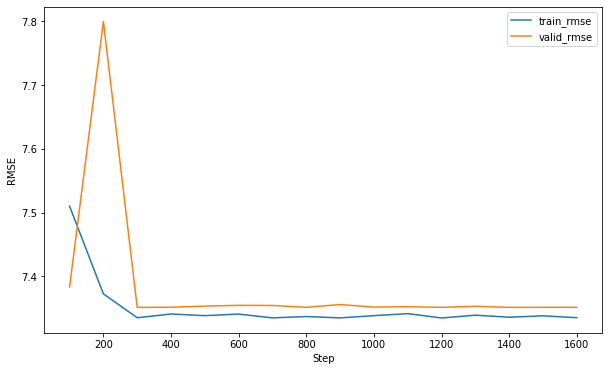

In [133]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(step_ls, train_RMSE) 
plt.plot(step_ls, val_RMSE) 
plt.legend(['train_rmse','valid_rmse'])
plt.xlabel('Step')
plt.ylabel('RMSE')

## Reinforcement learning

In [136]:
df2

,time,current_num,valid,isWeekday,isWeekend,1,2,3,4,5,...,time_22:20:00,time_22:30:00,time_22:40:00,time_22:50:00,time_23:00:00,time_23:10:00,time_23:20:00,time_23:30:00,time_23:40:00,time_23:50:00
0,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,2018-01-01 23:40:00,6.0,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23755,2018-06-14 23:10:00,17.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
23756,2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
23757,2018-06-14 23:30:00,17.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
23758,2018-06-14 23:40:00,13.0,1,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
